<a href="https://colab.research.google.com/github/odeepak/Handwritten-Digit-Recognition-using-Neural-Network/blob/main/Handwritten_Digit_Recognition_using_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Handwritten digit recognition is a classic problem in machine learning and computer vision. It involves recognizing handwritten digits (0-9) from images or scanned documents. This task is widely used as a benchmark for evaluating machine learning models especially neural networks due to its simplicity and real-world applications such as postal code recognition and bank check processing. In this article we will implement Handwritten Digit Recognition using Neural Network.

**Step 1: Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

**Step 2: Load and Explore the Dataset**

In [ ]:
from google.colab import files
import pandas as pd

# Upload CSV file
uploaded = files.upload()

# Read CSV file
df = pd.read_csv(list(uploaded.keys())[0])

# Display dataset
df.head()

Saving Train (1).csv to Train (1).csv


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


The dataset contains 42,000 rows where each row represents an image.
The first column (label) indicates the digit (0-9) and the remaining columns represent pixel values of the image.
We separate these into X (pixel values) and y (labels).
X has 42,000 samples with 784 features (28x28 pixels) and y has 42,000 labels.

In [ ]:
import pandas as pd

# Load training dataset
train_data = pd.read_csv('/content/Train (1).csv')

# Display dataset shape
print("Shape of train_data:", train_data.shape)

# Separate features and target
X = train_data.iloc[:, 1:]
y = train_data.iloc[:, 0]

# Display shapes
print("Shape of X after separating features:", X.shape)
print("Shape of y:", y.shape)

# Display first 5 records
print(train_data.head())

Shape of train_data: (42000, 785)
Shape of X after separating features: (42000, 784)
Shape of y: (42000,)
   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      1       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       0       0       0   
2      1       0       0       0       0       0       0       0       0   
3      4       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0   

**Step 3: Preprocess the Data**

In [ ]:
if not isinstance(X, pd.DataFrame):
    X = pd.DataFrame(X)
X = X.apply(pd.to_numeric, errors='coerce')
X = X.fillna(0)
X = X.values / 255.0
X = X.reshape(-1, 28, 28, 1)
print("Shape of X after reshaping:", X.shape)

Shape of X after reshaping: (42000, 28, 28, 1)


**Step 4: One-Hot Encode the Labels**
Neural networks work best when labels are in a specific format called "one-hot encoding." Let’s convert our labels into this format.

In [ ]:
y = to_categorical(y, num_classes=10)
print("Shape of y after one-hot encoding:", y.shape)

Shape of y after one-hot encoding: (42000, 10)


**Step 5: Split the Data**
To evaluate our model effectively we need to split the data into a training set and a validation set. Here we will use 80% data for training rest for testing.

In [11]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)

X_train shape: (33600, 28, 28, 1)


**Step 6: Build the Neural Network Model**
Now let’s define the architecture of our neural network. We define a simple feedforward neural network with three layers:

A Flatten layer converts the 28x28 image into a single vector of length 784.
Two hidden layers with 128 and 64 neurons use the ReLU activation function to introduce non-linearity.
An output layer with 10 neurons uses the softmax activation function to predict probabilities for each digit (0-9).
We compile the model with the Adam optimizer, categorical cross-entropy loss, and accuracy as the evaluation metric.

In [15]:
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
print(type(X_train))
print(X_train.shape)
print(X_train[:5])

<class 'numpy.ndarray'>
(33600, 28, 28, 1)
[[[[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  ...

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]]


 [[[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  ...

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]]


 [[[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  ...

  [[0.]
   [0.]
   [0.]
   ...
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [

In [21]:
import numpy as np

print("X_train shape:", X_train.shape)
print("Data type:", X_train.dtype)
print("Missing values:", np.isnan(X_train).sum())
print("Infinite values:", np.isinf(X_train).sum())

X_train shape: (33600, 28, 28, 1)
Data type: float64
Missing values: 0
Infinite values: 0


**Step 6: Build the Neural Network Model**
Now let’s define the architecture of our neural network. We define a simple feedforward neural network with three layers:

A Flatten layer converts the 28x28 image into a single vector of length 784.
Two hidden layers with 128 and 64 neurons use the ReLU activation function to introduce non-linearity.
An output layer with 10 neurons uses the softmax activation function to predict probabilities for each digit (0-9).
We compile the model with the Adam optimizer, categorical cross-entropy loss, and accuracy as the evaluation metric.

In [24]:
model = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

**Step 7: Train the Model**

In [25]:
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val))

Epoch 1/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9111 - loss: 0.3063 - val_accuracy: 0.9485 - val_loss: 0.1736
Epoch 2/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9624 - loss: 0.1266 - val_accuracy: 0.9615 - val_loss: 0.1316
Epoch 3/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9725 - loss: 0.0860 - val_accuracy: 0.9663 - val_loss: 0.1151
Epoch 4/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9805 - loss: 0.0624 - val_accuracy: 0.9675 - val_loss: 0.1076
Epoch 5/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9845 - loss: 0.0485 - val_accuracy: 0.9676 - val_loss: 0.1162
Epoch 6/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9876 - loss: 0.0382 - val_accuracy: 0.9713 - val_loss: 0.1009
Epoch 7/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9894 - loss: 0.0332 - val_accuracy: 0.9724 - val_loss: 0.1077
Epoch 8/10
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9906 - loss: 0.0282 - 

**Step 8: Evaluate the Model**
Once training is complete we evaluate the model’s performance on the validation set and plot the training and validation accuracy to see how well the model learned over time. This helps us identify issues like overfitting.

263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9721 - loss: 0.1220
Validation Accuracy: 97.21%


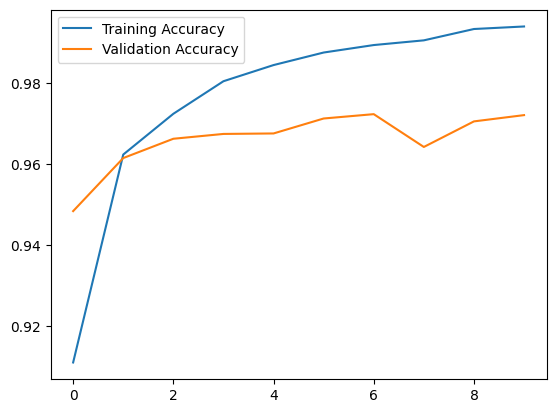

In [26]:
val_loss, val_accuracy = model.evaluate(X_val, y_val)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

The blue line represents the training accuracy which consistently increases over the training steps while the orange line represents the validation accuracy which fluctuates slightly but shows a positive trend. By the end of the training the model achieves a training accuracy of around 96.81% and a validation accuracy of 97.13% indicating the model performs well on both training and validation data suggesting good generalization capability.



**Step 9: Make Predictions**
Let’s use the trained model to make predictions on new data. We load the test data preprocess it similarly to the training data and feed it into the model to get predictions.

In [32]:
import pandas as pd
import numpy as np

train_data = pd.read_csv('/content/Train (1).csv')

print(train_data.shape)
print(train_data.head())

(42000, 785)
   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      1       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       0       0       0   
2      1       0       0       0       0       0       0       0       0   
3      4       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0         0   

   pixel780  pixel781  pixel782  pixel783  
0         0      

In [33]:
X = train_data.iloc[:, 1:]
y = train_data.iloc[:, 0]

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [35]:
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [37]:
print("Model input shape:", model.input_shape)
print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)

Model input shape: (None, 28, 28, 1)
X_train shape: (33600, 784)
X_test shape: (8400, 784)


In [38]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [39]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,849 (433.00 KB)

 Trainable params: 110,849 (433.00 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/50
840/840 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.1131 - loss: -29371918.0000 - val_accuracy: 0.1100 - val_loss: -158887072.0000
Epoch 2/50
840/840 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.1129 - loss: -926582272.0000 - val_accuracy: 0.1100 - val_loss: -2335757312.0000
Epoch 3/50
840/840 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.1129 - loss: -5362819584.0000 - val_accuracy: 0.1100 - val_loss: -9766550528.0000
Epoch 4/50
840/840 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.1129 - loss: -16466483200.0000 - val_accuracy: 0.1100 - val_loss: -25579008000.0000
Epoch 5/50
840/840 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.1129 - loss: -37403922432.0000 - val_accuracy: 0.1100 - val_loss: -53030678528.0000
Epoch 6/50
840/840 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.1129 - loss: -71107149824.0000 - val_accuracy: 0.1100 - val_loss: -94928068608.0000
Epoch 7/50
840/840 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.1129 - loss: -120457781248.0000 - val_accu

In [41]:
predictions = model.predict(X_test_scaled)

predicted_labels = (predictions > 0.5).astype(int)

print(predicted_labels[:10])

263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
[[1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]]


In [47]:
model = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
import pandas as pd

test_data = pd.read_csv('/content/Train (1).csv')

print("Dataset Shape:", test_data.shape)
print(test_data.head())
print(test_data.columns)

Dataset Shape: (42000, 785)
   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      1       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       0       0       0   
2      1       0       0       0       0       0       0       0       0   
3      4       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0         0   

   pixel780  pixel781  pixel782  pixel783  
0 

In [51]:
import numpy as np
import matplotlib.pyplot as plt

# Separate pixel values
X_test = test_data.iloc[:, 1:].values

# Normalize pixel values
X_test = X_test / 255.0

# Reshape images
X_test = X_test.reshape(-1, 28, 28, 1)

# Predict digits
predictions = model.predict(X_test)

# Get predicted labels
predicted_labels = np.argmax(predictions, axis=1)

1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step


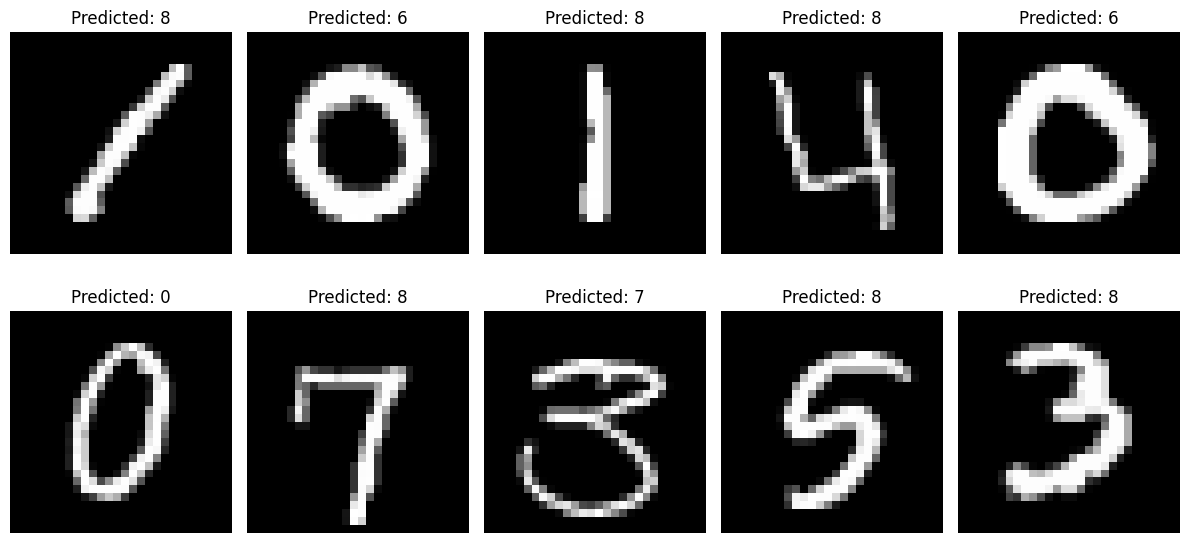

In [52]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {predicted_labels[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [53]:
print(test_data.shape)

(42000, 785)


In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test_data = pd.read_csv('/content/Train (1).csv')

X_test = test_data.iloc[:, 1:].values

X_test = X_test / 255.0

X_test = X_test.reshape(-1, 28, 28, 1)

print("X_test shape:", X_test.shape)

X_test shape: (42000, 28, 28, 1)


In [55]:
predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)

print(predicted_labels[:10])

1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step
[8 6 8 8 6 0 8 7 8 8]


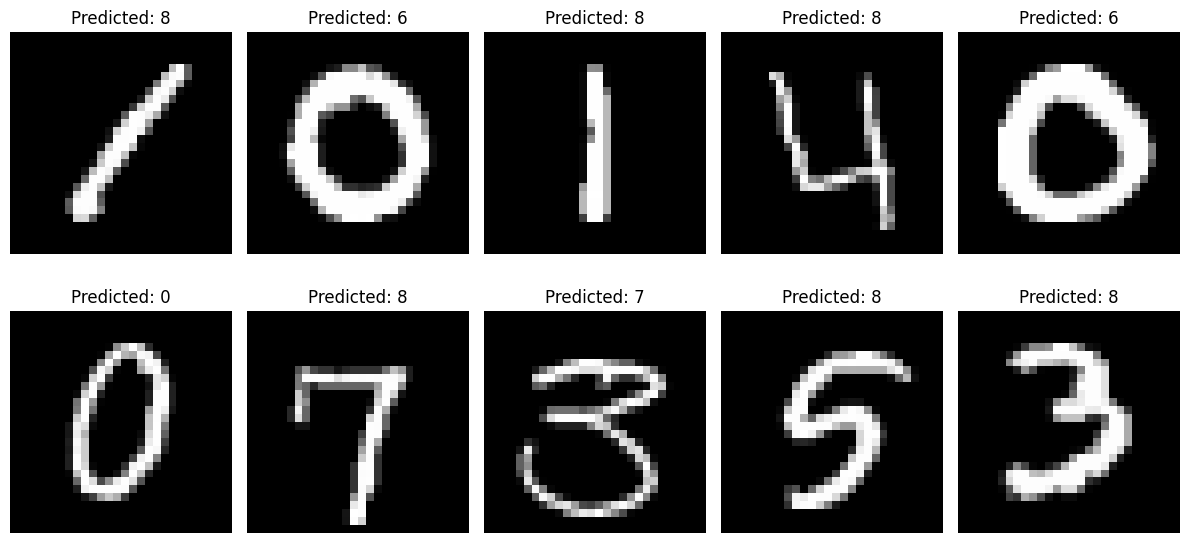

In [56]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i+1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(f"Predicted: {predicted_labels[i]}")

    plt.axis('off')

plt.tight_layout()
plt.show()

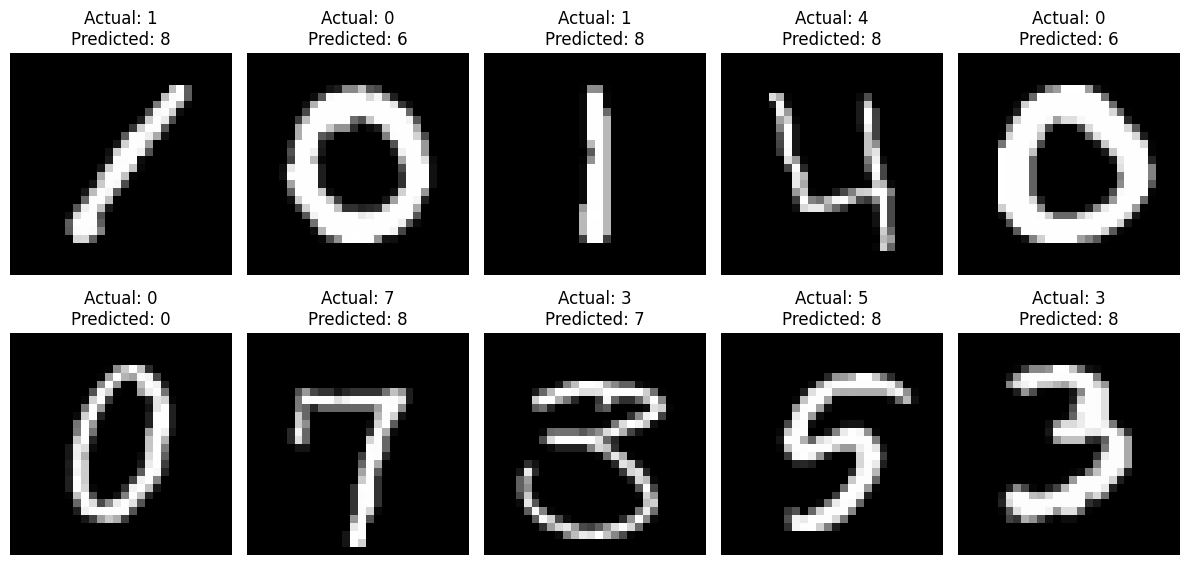

In [57]:
actual_labels = test_data.iloc[:, 0].values

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i+1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {actual_labels[i]}\nPredicted: {predicted_labels[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()